# Import Library & Import Data

In [6]:
# Data Processing
import pandas as pd
import numpy as np

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Datetime Standardize
import datetime

In [7]:
# Import Library & Import Data
import sys
import matplotlib

print(f"Python version: {sys.version.split()[0]}")
print(f"pandas version: {pd.__version__}")
print(f"matplotlib version: {matplotlib.__version__}")
print(f"numpy version: {np.__version__}")

Python version: 3.13.16
pandas version: 2.2.3
matplotlib version: 3.10.0
numpy version: 2.1.3


In [8]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [9]:
# Tải các bảng dữ liệu
product = pd.read_csv('/content/drive/MyDrive/K04 - Scripts các buổi học/Dataset/Buổi 4: Phân tích ABC/Product.csv')
ecom_sales = pd.read_csv('/content/drive/MyDrive/K04 - Scripts các buổi học/Dataset/Buổi 4: Phân tích ABC/EcomSales.csv')

print("Dữ liệu đã sẵn sàng!")

Dữ liệu đã sẵn sàng!


# Data Checking

# Data Preprocessing / Wrangling

In [10]:
ecom_sales.head(2)

,RowID,OrderID,OrderDate,CustomerID,Segment,RegionCode,ProductCode,Quantity,Sales,Discount,Profit
0,25221,IN-2012-TH211151-41003,4/4/2020,TH-211151,Corporate,RRR0001,P000001,13,416,0.0,208.0
1,29464,ID-2013-BD116051-41518,9/1/2021,BD-116051,Consumer,R0002,PPP000002,4,20,0.0,10.0


# Exploratory - EDA (Đưa vào phương pháp phân tích or thống kê)

In [11]:
df = ecom_sales.merge(product, on = 'ProductCode', how = 'left')

df_fillna = df.fillna('Other')

df_filter = df_fillna[['OrderID', 'Subcategory']]

df_prep = df_filter.drop_duplicates().reset_index(drop = True)

df_prep

,OrderID,Subcategory
0,IN-2012-TH211151-41003,"bath oils, bubbles and soaks"
1,ID-2013-BD116051-41518,Other
2,IN-2015-TS212051-42173,"bath oils, bubbles and soaks"
3,IN-2014-SU206651-41899,body moisturizers
4,IN-2015-GM144551-42217,body moisturizers
...,...,...
47969,ZA-2015-BT1395147-42164,shampoos and conditioners
47970,ZA-2015-NG8430147-42332,foundations and concealers
47971,ZA-2015-BT1305147-42338,Eye shadows and pencils
47972,ZA-2015-GR4560147-42216,Nail care products


In [12]:
df_test = df_prep[df_prep['OrderID'] == 'IN-2012-TH211151-41003']

df_test

,OrderID,Subcategory
0,IN-2012-TH211151-41003,"bath oils, bubbles and soaks"
9,IN-2012-TH211151-41003,Other
12,IN-2012-TH211151-41003,Nail care products
40,IN-2012-TH211151-41003,"candles, sprays, diffusers"
45,IN-2012-TH211151-41003,Eye shadows and pencils


In [13]:
# Self join test 1 đơn:

df_combo = df_test.merge(df_test, on = 'OrderID', how = 'inner')

df_combo_filter = df_combo[df_combo['Subcategory_x'] < df_combo['Subcategory_y']]

df_combo_count = df_combo_filter.groupby(by = ['Subcategory_x', 'Subcategory_y'], as_index = False).agg(count_order = ('OrderID', 'nunique')).sort_values(by = 'count_order', ascending = False)

df_combo_count

,Subcategory_x,Subcategory_y,count_order
0,Eye shadows and pencils,Nail care products,1
1,Eye shadows and pencils,Other,1
2,Eye shadows and pencils,"bath oils, bubbles and soaks",1
3,Eye shadows and pencils,"candles, sprays, diffusers",1
4,Nail care products,Other,1
5,Nail care products,"bath oils, bubbles and soaks",1
6,Nail care products,"candles, sprays, diffusers",1
7,Other,"bath oils, bubbles and soaks",1
8,Other,"candles, sprays, diffusers",1
9,"bath oils, bubbles and soaks","candles, sprays, diffusers",1


In [14]:
# Self join full bảng:

df_combo = df_prep.merge(df_prep, on = 'OrderID', how = 'inner')

df_combo_filter = df_combo[df_combo['Subcategory_x'] < df_combo['Subcategory_y']]

df_combo_count = df_combo_filter.groupby(by = ['Subcategory_x', 'Subcategory_y'], as_index = False).agg(count_order = ('OrderID', 'nunique')).sort_values(by = 'count_order', ascending = False)

df_combo_count['combo_name'] = df_combo_count['Subcategory_x'] + ' -> ' + df_combo_count['Subcategory_y']

df_combo_count

,Subcategory_x,Subcategory_y,count_order,combo_name
60,Nail care products,"bath oils, bubbles and soaks",716,"Nail care products -> bath oils, bubbles and s..."
69,Nail care products,hand creams,701,Nail care products -> hand creams
61,Nail care products,body moisturizers,693,Nail care products -> body moisturizers
70,Nail care products,shampoos and conditioners,685,Nail care products -> shampoos and conditioners
71,Nail care products,vitamins and supplements,641,Nail care products -> vitamins and supplements
...,...,...,...,...
73,Other,"candles, sprays, diffusers",1,"Other -> candles, sprays, diffusers"
33,Eye shadows and pencils,Other,1,Eye shadows and pencils -> Other
74,Other,face masks and exfoliators,1,Other -> face masks and exfoliators
72,Other,"bath oils, bubbles and soaks",1,"Other -> bath oils, bubbles and soaks"


/tmp/ipykernel_775/601619197.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


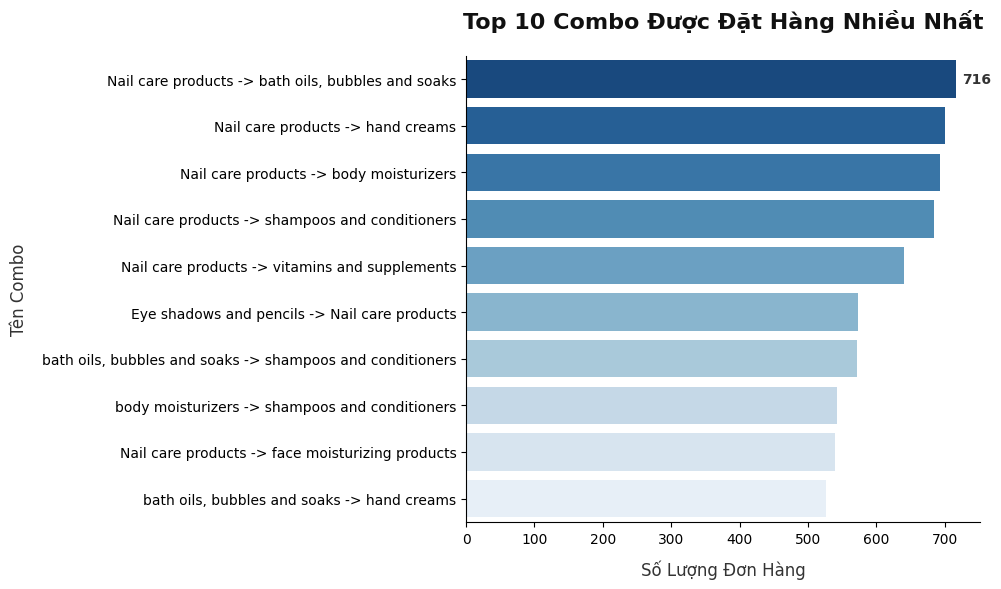

In [15]:
# 1. Khởi tạo kích thước biểu đồ rộng rãi để tránh font chữ bị đè/cắt
plt.figure(figsize=(10, 6))

# 2. Sử dụng bảng màu gradient mượt mà (chuyển từ đậm sang nhạt) thay vì màu mặc định
# Bạn có thể đổi 'Blues_r' thành 'crest', 'viridis', hoặc 'flare' tùy sở thích
ax = sns.barplot(
    data=df_combo_count.head(10),
    x='count_order',
    y='combo_name',
    palette='Blues_r'
)

# 3. Thêm nhãn số liệu (Data Labels) trực tiếp vào đầu mỗi thanh để người xem dễ đọc
ax.bar_label(ax.containers[0], padding=5, fontsize=10, color='#333333', weight='bold')

# 4. Tinh chỉnh tiêu đề và nhãn trục (Font lớn hơn, khoảng cách thoáng)
plt.title('Top 10 Combo Được Đặt Hàng Nhiều Nhất', fontsize=16, weight='bold', pad=20, color='#111111')
plt.xlabel('Số Lượng Đơn Hàng', fontsize=12, labelpad=10, color='#333333')
plt.ylabel('Tên Combo', fontsize=12, labelpad=10, color='#333333')

# 5. Làm sạch biểu đồ: Ẩn đường viền trên và phải (Despine) để tạo không gian mở
sns.despine(left=False, bottom=False)

# 6. Tự động căn chỉnh các thành phần không bị tràn khung
plt.tight_layout()

# Hiển thị biểu đồ
plt.show()

# Feature Engineering (Optional)

# Conclusion & Recommendation